In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import roc_curve, auc,  roc_auc_score
from scipy.stats import randint,uniform

df=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv',index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')
df.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,4,1,2,0,2,0,0,0,0,0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,7,3,2,1,0,5,1,1,0,0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,7,3,1,1,0,5,1,0,0,0
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,4,1,1,1,2,1,1,0,0,0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,1,4,0,1,0,1,0,0,0,0


## 🛑 **Process to obtain the best model**

### 🛑FEATURE SELECTION

1. Improves Model Accuracy: By removing irrelevant features, the model can focus on the most important data points, leading to better performance.

2. Reduces Overfitting: Too many features can prevent your model from learning noise in the data. Reducing the feature set can help mitigate overfitting.
Speeds up Training: Less data means faster computation. Feature selection can significantly reduce the training time, especially with large datasets.

3. Enhances Interpretability: With fewer features, it’s easier to understand how the model makes decisions

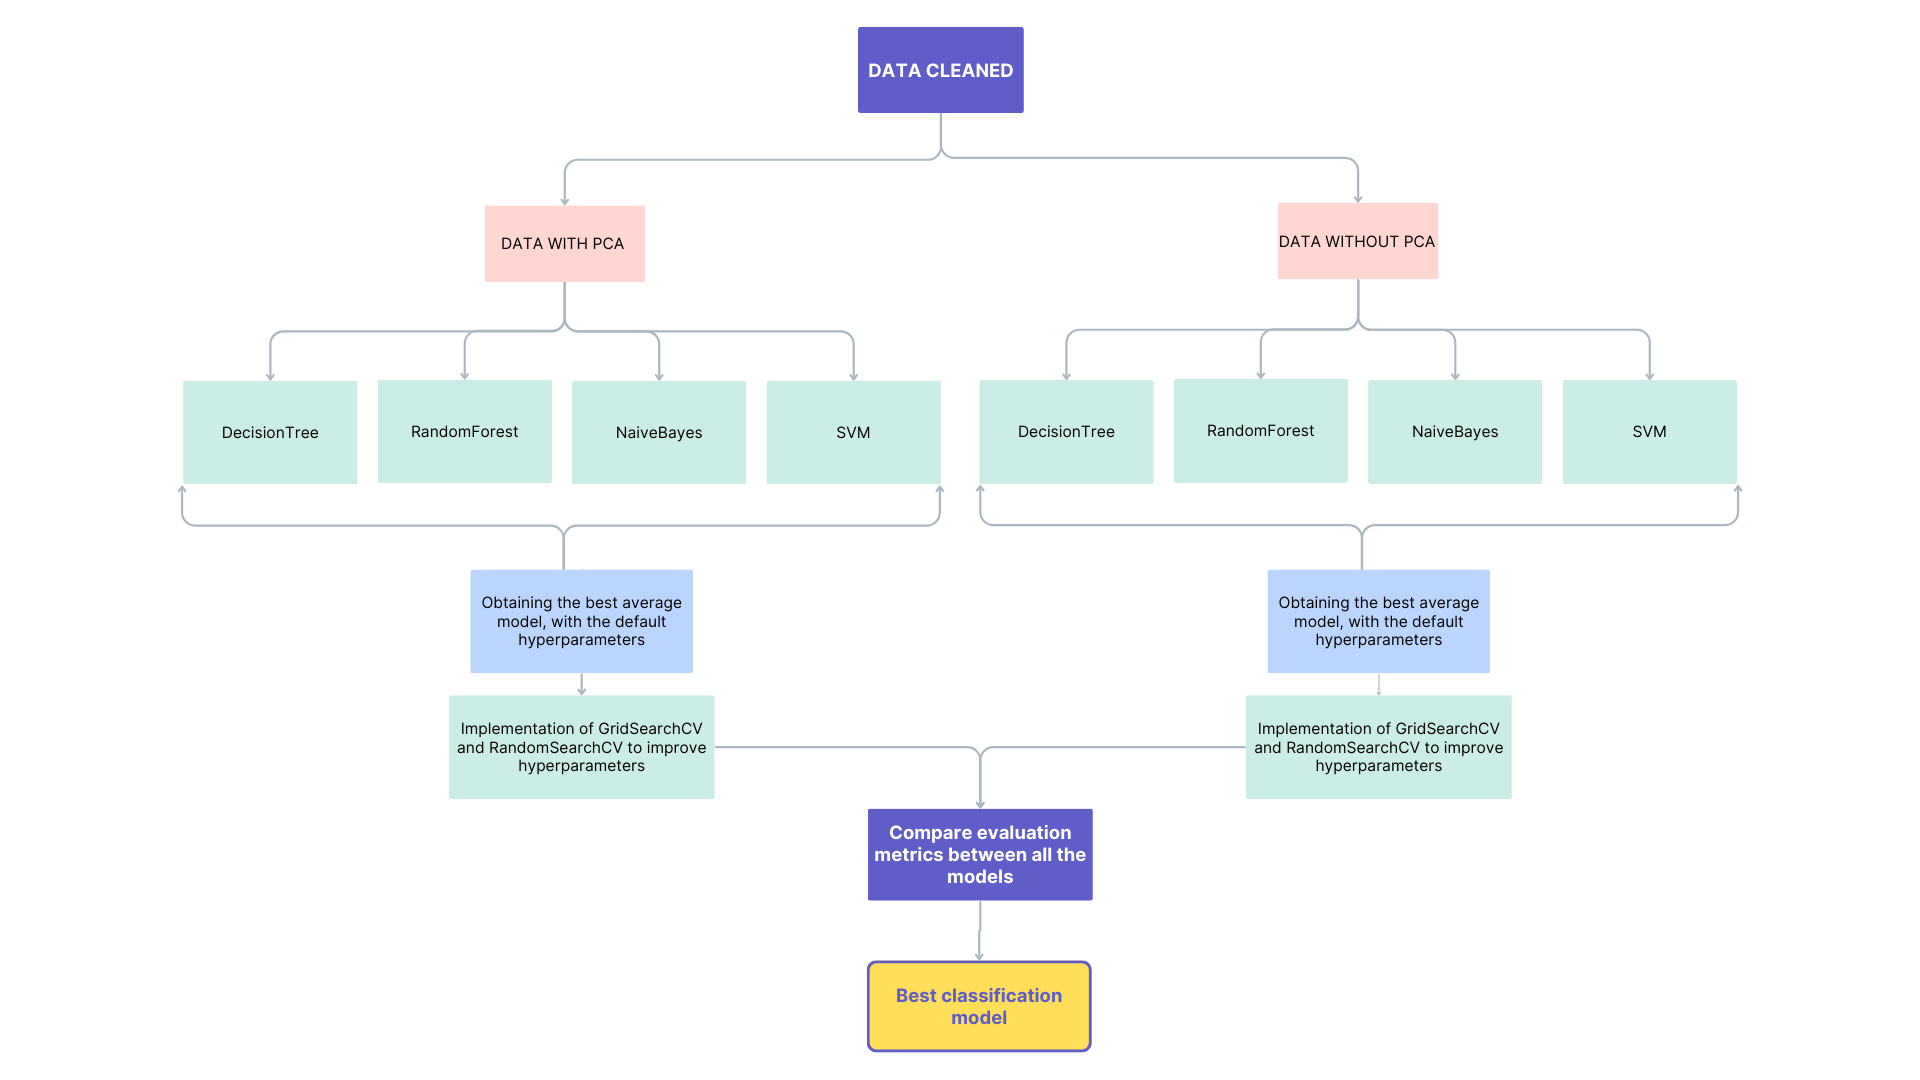

## 🛑 Task 1.3. PCA:  **Prediction of TypeDzClass**

---



### 🛑 DATA SPLICING WE WILL USE STRATIFIED KFOLD

- First, we separate the data into the target variable and the features. It is crucial to identify and save the names of the qualitative columns, since principal component analysis (PCA) cannot be applied to them.

In [2]:
target=df['dzclass']
features=df.drop(['ca','dzgroup','dzclass'],axis=1)
categorical_features_cols= categorical_features.drop(['ca','dzgroup','dzclass'],axis=1).columns

- We are using a 70/10/20 data split strategy, but this time, we will apply a stratified k-fold approach. Specifically, we will calculate 10 folds: 5 external folds and 2 internal folds for validation. 
    
    The external folds will determine the training and testing splits, while the internal folds will further divide the training data into training and validation sets. This ensures a robust evaluation process by maintaining the data distribution and minimizing potential biases.


Cumulative explained variance for each number of components: [0.13607659 0.22775614 0.30747383 0.37742491 0.43116072 0.48231257
 0.53052046 0.57512772 0.61874295 0.66152158 0.70245633 0.7397693
 0.77560909 0.81050037 0.8441526  0.87704039 0.90762293 0.93627235
 0.96181796 0.98659058 0.99610197 1.        ]


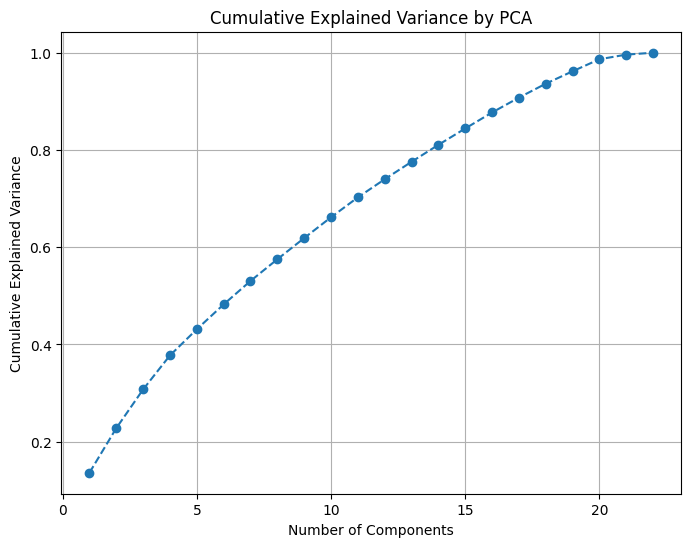

The optimal number of components to capture 85% of the variance is: 16


/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75834/3471206869.py:111: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)


Cumulative explained variance for each number of components: [0.13722314 0.22934956 0.3141797  0.38457109 0.43615795 0.48696822
 0.53531336 0.58079857 0.62360202 0.66609601 0.70639186 0.74471057
 0.78106343 0.81648691 0.85033265 0.8827955  0.91192103 0.93985649
 0.96489735 0.98701647 0.99609915 1.        ]


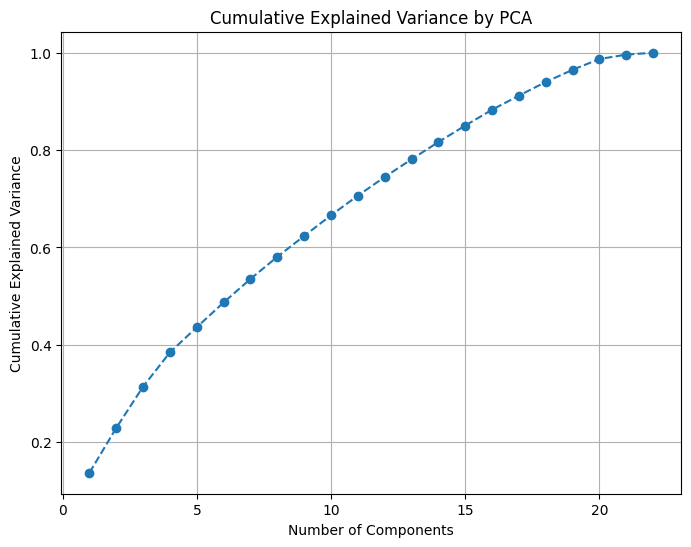

The optimal number of components to capture 85% of the variance is: 15
Cumulative explained variance for each number of components: [0.13179284 0.22334829 0.30593305 0.37616912 0.43017803 0.48224568
 0.5295317  0.57540177 0.61878512 0.65912883 0.69860291 0.73698238
 0.77465817 0.81154526 0.84471268 0.87736439 0.90736688 0.93621327
 0.96181993 0.98578741 0.99588649 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


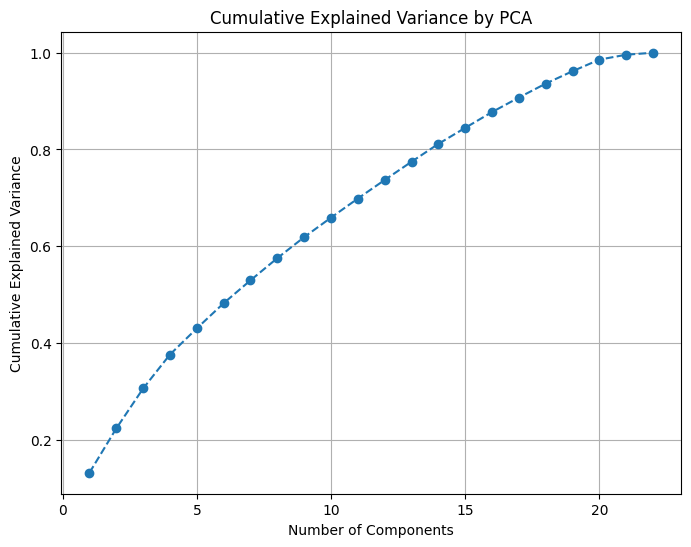

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13946093 0.23086551 0.31437864 0.3818054  0.43446922 0.48497533
 0.53202152 0.57715313 0.62159207 0.66477017 0.70489356 0.74243561
 0.77973681 0.81552528 0.84867121 0.88067365 0.91141689 0.94055394
 0.96484727 0.98870682 0.99609018 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


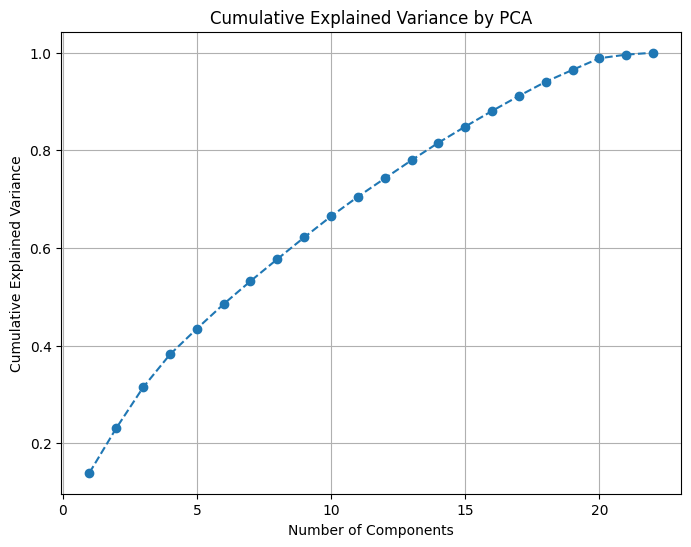

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.14028344 0.23153726 0.31306161 0.38194839 0.4352162  0.48610373
 0.5335323  0.57937574 0.62253597 0.66436224 0.70455819 0.74182212
 0.77876268 0.81370273 0.84699957 0.87888484 0.9090567  0.93724749
 0.96289474 0.98742562 0.99618693 1.        ]


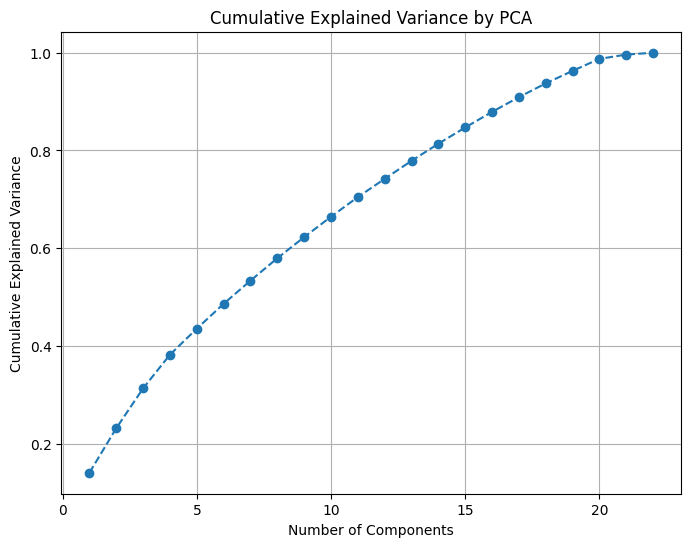

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13602671 0.22801156 0.31017187 0.37907374 0.43191367 0.48385046
 0.53307502 0.57809286 0.62104098 0.66258442 0.70340929 0.74110499
 0.77771611 0.81227138 0.84607696 0.8788574  0.90853057 0.93698462
 0.96171256 0.98475536 0.9957151  1.        ]


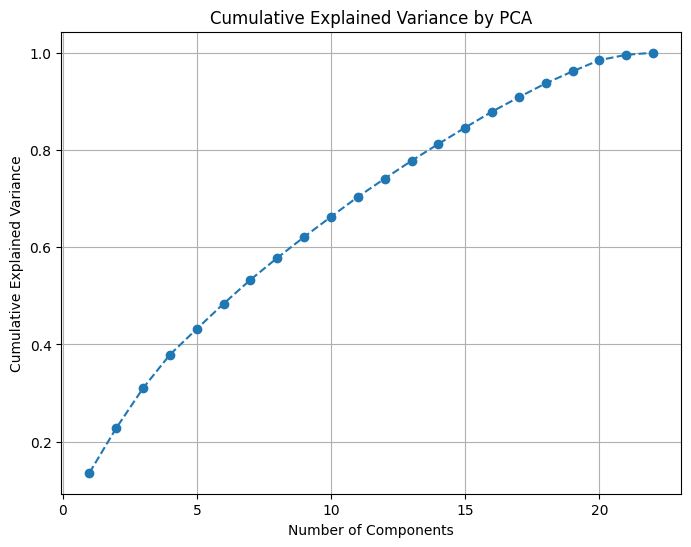

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13926966 0.22998212 0.31489677 0.38328983 0.43572825 0.48646125
 0.53527859 0.5800575  0.62301257 0.66476831 0.70500425 0.74379954
 0.78094132 0.8163751  0.85006089 0.88193822 0.91121221 0.9395948
 0.9639911  0.98699981 0.99618635 1.        ]


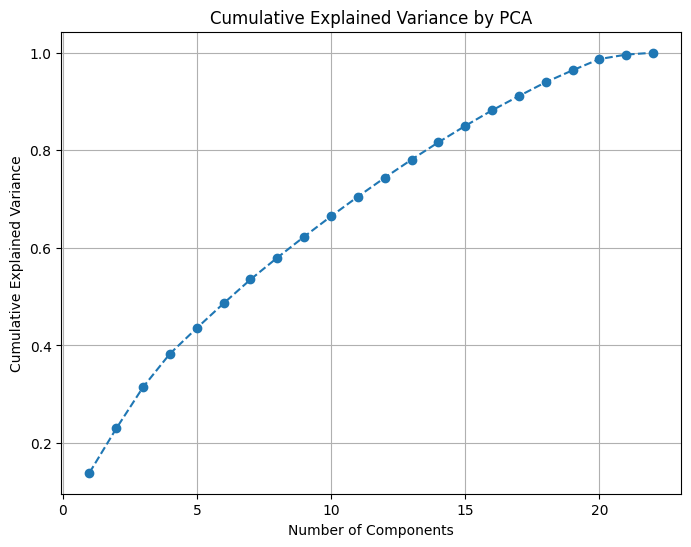

The optimal number of components to capture 85% of the variance is: 15
Cumulative explained variance for each number of components: [0.13429822 0.22524483 0.30492742 0.37453945 0.42717807 0.47883921
 0.52765611 0.57307773 0.61749644 0.66071227 0.70122352 0.73899456
 0.77510619 0.81048875 0.84457797 0.87637641 0.90619329 0.93448488
 0.9606504  0.98592394 0.99586451 1.        ]


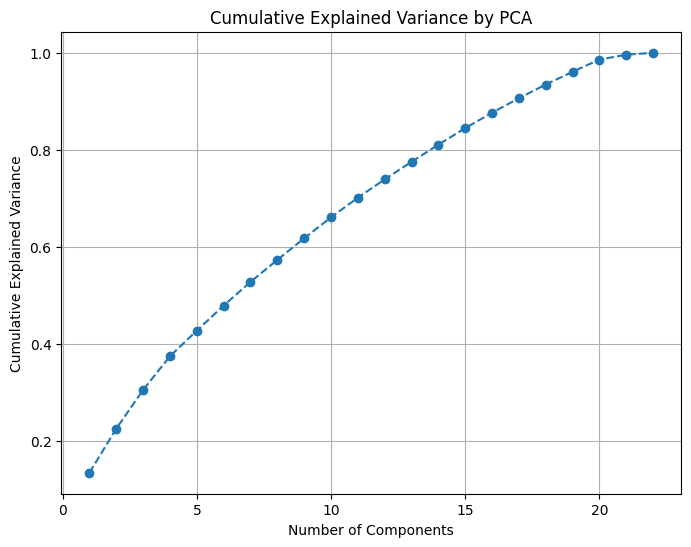

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13775035 0.22869058 0.3114517  0.38020753 0.43390575 0.48493116
 0.53249095 0.57739474 0.62070558 0.66236329 0.70334118 0.74126264
 0.77870576 0.81457696 0.84811865 0.88069913 0.91094379 0.93951284
 0.96394966 0.98700443 0.99598146 1.        ]


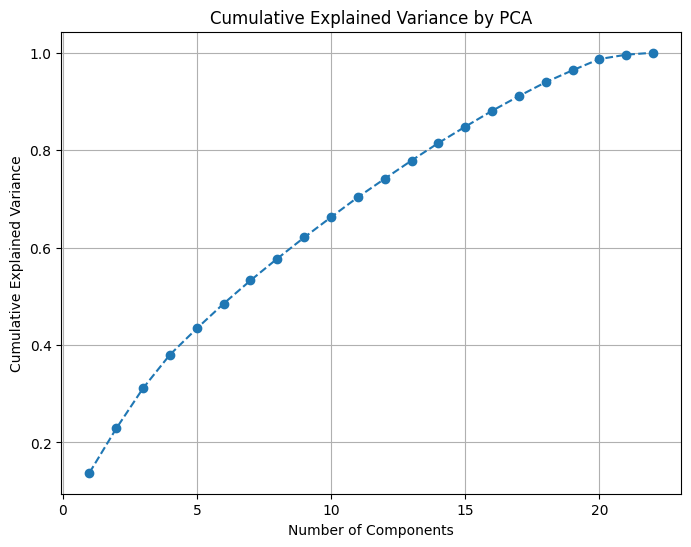

The optimal number of components to capture 85% of the variance is: 16
Cumulative explained variance for each number of components: [0.13326004 0.22501572 0.30341366 0.37290101 0.42672642 0.47835053
 0.52740419 0.57270433 0.61740536 0.65968007 0.69994058 0.73858583
 0.77528844 0.81112782 0.84436413 0.87600054 0.90613635 0.93600513
 0.96223905 0.98747237 0.99599217 1.        ]


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


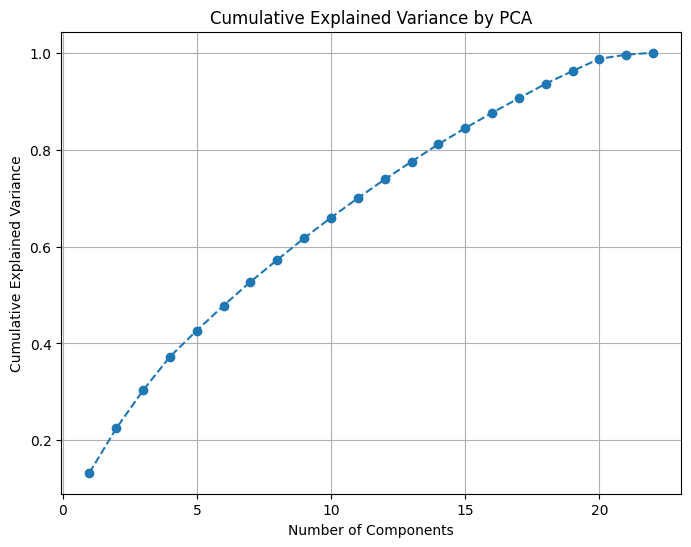

The optimal number of components to capture 85% of the variance is: 16
            Model  Accuracy  Precision    Recall  F1 Score
0   Decision Tree  0.550511   0.558483  0.550511  0.554297
1   Random Forest  0.708854   0.697886  0.708854  0.683879
2     Naïve Bayes  0.566402   0.597803  0.566402  0.571707
3             SVM  0.727582   0.728594  0.727582  0.702911
4   Decision Tree  0.560726   0.558837  0.560726  0.559738
5   Random Forest  0.698638   0.683795  0.698638  0.671357
6     Naïve Bayes  0.535187   0.578505  0.535187  0.542334
7             SVM  0.727015   0.678196  0.727015  0.699432
8   Decision Tree  0.547673   0.557726  0.547673  0.551969
9   Random Forest  0.690692   0.709976  0.690692  0.662383
10    Naïve Bayes  0.381385   0.631524  0.381385  0.362829
11            SVM  0.712259   0.662856  0.712259  0.684806
12  Decision Tree  0.550511   0.553926  0.550511  0.552007
13  Random Forest  0.689557   0.707359  0.689557  0.661966
14    Naïve Bayes  0.582860   0.609500  0.58

In [3]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_pca = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])
# Diccionario para almacenar los DataFrames procesados
pca_data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        scaler = StandardScaler()
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_test = scaler.transform(X_test_quantitative)

        # Aplicar PCA
        pca = PCA()
        pca.fit(X_scaled_train)

        # Obtener y mostrar la varianza acumulada
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = explained_variance.cumsum()
        print(f"Cumulative explained variance for each number of components: {cumulative_variance}")

        # Graficar la varianza acumulada
        plt.figure(figsize=(8, 6))
        plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
        plt.title('Cumulative Explained Variance by PCA')
        plt.xlabel('Number of Components')
        plt.ylabel('Cumulative Explained Variance')
        plt.grid(True)
        plt.show()

        # Determinar el número óptimo de componentes
        optimal_components = next(i for i, value in enumerate(cumulative_variance) if value >= 0.85) + 1
        print(f"The optimal number of components to capture 85% of the variance is: {optimal_components}")

        # Aplicar PCA con el número óptimo de componentes
        pca_optimal = PCA(n_components=optimal_components)
        X_pca_optimal_train = pca_optimal.fit_transform(X_scaled_train)
        X_pca_optimal_val = pca_optimal.transform(X_scaled_val)
        X_pca_optimal_test = pca_optimal.transform(X_scaled_test)

        # Crear DataFrames para las componentes principales
        original_X_train_index = X_train.index
        original_X_val_index = X_val.index
        original_X_test_index = X_test.index

        pca_X_train = pd.DataFrame(X_pca_optimal_train, index=original_X_train_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_train = pd.concat([pca_X_train, X_train_qualitative], axis=1)

        pca_X_val = pd.DataFrame(X_pca_optimal_val, index=original_X_val_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_val = pd.concat([pca_X_val, X_val_qualitative], axis=1)

        pca_X_test = pd.DataFrame(X_pca_optimal_test, index=original_X_test_index, columns=[f'PC{i+1}' for i in range(optimal_components)])
        pca_X_test = pd.concat([pca_X_test, X_test_qualitative], axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': pca_X_train,
            'Train_Y': y_train,
            'Validation_X': pca_X_val,
            'Validation_Y': y_val,
            'Test_X': pca_X_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        pca_data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(pca_X_train, y_train)
        y_pred_dt = model_dt.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_dt,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_dt,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(pca_X_train, y_train)
        y_pred_rf = model_rf.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_rf,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_rf,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(pca_X_train, y_train)
        y_pred_nb = model_nb.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_nb,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_nb,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(pca_X_train, y_train)
        y_pred_svm = model_svm.predict(pca_X_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_svm,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_svm,average = 'weighted')
        }])
        evaluation_metrics_pca = pd.concat([evaluation_metrics_pca, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_pca)



#### 🛑 Results for predefinded Models

In [4]:
# Promedios por modelo
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.558408,0.562240,0.558408,0.560040
Naïve Bayes,0.523730,0.598587,0.523730,0.525030
Random Forest,0.690147,0.686722,0.690147,0.662710
SVM,0.713589,0.697713,0.713589,0.687815


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model

- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **SVM** model. These model demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.3 PCA Hyperparameter Turning

`````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_pca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_pca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_pca_SVM = pd.concat([df_hyperparameters_gridsearch_pca_SVM, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_pca_SVM = pd.concat([df_hyperparameters_randomsearch_pca_SVM, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch_pca_SVM)
df_hyperparameters_gridsearch_pca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /GRIDSEARCH_PCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch_pca_SVM)
df_hyperparameters_randomsearch_pca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /RANDOMSEARCH_PCA_SVM.csv')

In [5]:
df_hyperparameters_gridsearch_pca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /GRIDSEARCH_PCA_SVM.csv')
df_hyperparameters_randomsearch_pca_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /RANDOMSEARCH_PCA_SVM.csv')

In [6]:
df_hyperparameters_gridsearch_pca_SVM[df_hyperparameters_gridsearch_pca_SVM['Accuracy'] == df_hyperparameters_gridsearch_pca_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
8,8,Fold_Externo_4-Fold_Interno_1,1,rbf,3,scale,0.711692


In [7]:
df_hyperparameters_randomsearch_pca_SVM[df_hyperparameters_randomsearch_pca_SVM['Accuracy'] == df_hyperparameters_randomsearch_pca_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
8,8,Fold_Externo_4-Fold_Interno_1,54.40241,linear,3,scale,0.707722


### 🟢 Evaluation of SVM  Model for TypeDzClass Prediction with PCA (Hyperparameter Tuning)

- USE OF PARAMETERS GIVEN BY THE **GRIDSEARCH SVM**

In [8]:
SVM_df_hyperparameter_turning = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'scale',
                 kernel= 'rbf')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        recall_GS = recall_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        f1_GS = f1_score(data['Test_Y'], y_pred_GS,average = 'weighted')

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS]
        })
        SVM_df_hyperparameter_turning=pd.concat([SVM_df_hyperparameter_turning,new_row], ignore_index=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75834/1898433773.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  SVM_df_hyperparameter_turning=pd.concat([SVM_df_hyperparameter_turning,new_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision

- USE OF PARAMETERS GIVEN BY THE **RANDOMSEARCH SVM**

In [9]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=54.40241,
            degree=3,
            gamma='scale',
            kernel='linear'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average = 'weighted')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average = 'weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average = 'weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS
        }])

        # Concatenar los resultados
        SVM_df_hyperparameter_turning = pd.concat([SVM_df_hyperparameter_turning, new_row], ignore_index=True)


SVM_df_hyperparameter_turning.groupby('Model').mean()


/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Super Vector Machine GS,0.713589,0.697713,0.713589,0.687815
Support Vector Machine RS,0.707571,0.659468,0.707571,0.682248


## 🛑 Task 1.3. WITHOUT PCA:  **Prediction of HospDeath**

---



### 🛑 DATA SPLICING

- First, we separate the data into the target variable and the features.

In [10]:
target=df['dzclass']
features=df.drop(['ca','dzgroup','dzclass'],axis=1)
categorical_features_cols= categorical_features.drop(['ca','dzgroup','dzclass'],axis=1).columns

In [11]:
# Inicialización de StratifiedKFold externo
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_metrics_scaled= pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])
# Diccionario para almacenar los DataFrames procesados
data_dict = {}


# Inicio del proceso de K-Fold externo
for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, target)):
    
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    # K-Fold interno
    for train_index, val_index in kfold_internal.split(X_train_val, y_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]
        
        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features.columns]
        X_val_quantitative = X_val[numerical_features.columns]
        X_test_quantitative = X_test[numerical_features.columns]
        X_train_qualitative = X_train[categorical_features_cols]
        X_val_qualitative = X_val[categorical_features_cols]
        X_test_qualitative = X_test[categorical_features_cols]

        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict
        

        # Evaluar modelos
        # Decision Tree
        model_dt = DecisionTreeClassifier(random_state=42)
        model_dt.fit(X_scaled_train, y_train)
        y_pred_dt = model_dt.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Decision Tree',
            'Accuracy': accuracy_score(y_test, y_pred_dt),
            'Precision': precision_score(y_test, y_pred_dt,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_dt,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_dt,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Random Forest
        model_rf = RandomForestClassifier(random_state=42)
        model_rf.fit(X_scaled_train, y_train)
        y_pred_rf = model_rf.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Random Forest',
            'Accuracy': accuracy_score(y_test, y_pred_rf),
            'Precision': precision_score(y_test, y_pred_rf,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_rf,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_rf,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # Naïve Bayes
        model_nb = GaussianNB()
        model_nb.fit(X_scaled_train, y_train)
        y_pred_nb = model_nb.predict(X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'Naïve Bayes',
            'Accuracy': accuracy_score(y_test, y_pred_nb),
            'Precision': precision_score(y_test, y_pred_nb,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_nb,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_nb,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)

        # SVM
        model_svm = SVC(random_state=42)
        model_svm.fit(X_scaled_train, y_train)
        y_pred_svm = model_svm.predict( X_scaled_test)
        model_row = pd.DataFrame([{
            'Model': 'SVM',
            'Accuracy': accuracy_score(y_test, y_pred_svm),
            'Precision': precision_score(y_test, y_pred_svm,average = 'weighted'),
            'Recall': recall_score(y_test, y_pred_svm,average = 'weighted'),
            'F1 Score': f1_score(y_test, y_pred_svm,average = 'weighted')
        }])
        evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1

# Mostrar resultados finales
print(evaluation_metrics_scaled)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75834/2163508823.py:83: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is

            Model  Accuracy  Precision    Recall  F1 Score
0   Decision Tree  0.628831   0.639069  0.628831  0.633376
1   Random Forest  0.738933   0.721337  0.738933  0.717016
2     Naïve Bayes  0.473326   0.586543  0.473326  0.481684
3             SVM  0.743473   0.743376  0.743473  0.718439
4   Decision Tree  0.639614   0.644437  0.639614  0.641861
5   Random Forest  0.748581   0.735336  0.748581  0.722796
6     Naïve Bayes  0.449489   0.586886  0.449489  0.457640
7             SVM  0.748014   0.698315  0.748014  0.720357
8   Decision Tree  0.641317   0.635100  0.641317  0.637853
9   Random Forest  0.742906   0.737911  0.742906  0.718051
10    Naïve Bayes  0.413167   0.551179  0.413167  0.404668
11            SVM  0.717934   0.668976  0.717934  0.691758
12  Decision Tree  0.637911   0.638874  0.637911  0.637886
13  Random Forest  0.740636   0.736222  0.740636  0.721083
14    Naïve Bayes  0.455732   0.568029  0.455732  0.458917
15            SVM  0.713394   0.665051  0.713394  0.6881

#### 🛑 Results for predefinded Models

In [12]:
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.627257,0.631138,0.627257,0.628868
Naïve Bayes,0.459590,0.578699,0.459590,0.464458
Random Forest,0.744013,0.740702,0.744013,0.722893
SVM,0.722216,0.699788,0.722216,0.696709


### 🛑 USING GridSearchCV and RandomizedSearchCV to improve the model
- Given the high computational load, all results obtained from the grid searches and random searches for each model studied will be stored in a CSV file to streamline the workflow.

- Given the results obtained from the models with their default arguments, we have decided to use Grid Search and Random Search for the **Random Forest and SVM** models. These models demonstrate better performance, and by applying these hyperparameter tuning techniques, we aim to improve the results achieved previously.

#### SVM 1.3 No PCA Hyperparameter Turning

``````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_Nopca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])
df_hyperparameters_randomsearch_Nopca_SVM = pd.DataFrame(columns=['Fold', 'C', 'Kernel', 'Degree', 'Gamma', 'Accuracy'])

# Modelo base
model_svm = SVC()

# Espacios de búsqueda
param_grid = {
    'C': [1, 10],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
    'degree': [3, 4, 5],
}

param_dist = {
    'C': uniform(0.1, 100),
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto', uniform(0.01, 1)],
    'degree': randint(2, 6),
}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_svm,
            param_grid=param_grid,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'C': grid_search.best_params_['C'],
            'Kernel': grid_search.best_params_['kernel'],
            'Degree': grid_search.best_params_['degree'],
            'Gamma': grid_search.best_params_['gamma'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_Nopca_SVM = pd.concat([df_hyperparameters_gridsearch_Nopca_SVM, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_svm,
            param_distributions=param_dist,
            n_iter=10,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'C': random_search.best_params_['C'],
            'Kernel': random_search.best_params_['kernel'],
            'Degree': random_search.best_params_['degree'],
            'Gamma': random_search.best_params_['gamma'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_Nopca_SVM = pd.concat([df_hyperparameters_randomsearch_Nopca_SVM, new_row_random], ignore_index=True)

# Mostrar resultados
print("Grid Search")
print(df_hyperparameters_gridsearch_Nopca_SVM)
df_hyperparameters_gridsearch_Nopca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /GRIDSEARCH_NoPCA_SVM.csv')

print("Random Search")
print(df_hyperparameters_randomsearch_Nopca_SVM)
df_hyperparameters_randomsearch_Nopca_SVM.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /RANDOMSEARCH_NoPCA_SVM.csv')

In [13]:
df_hyperparameters_gridsearch_NoPCA_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /GRIDSEARCH_NoPCA_SVM.csv')
df_hyperparameters_randomsearch_NoPCA_SVM=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /RANDOMSEARCH_NoPCA_SVM.csv')


In [14]:
df_hyperparameters_gridsearch_NoPCA_SVM[df_hyperparameters_gridsearch_NoPCA_SVM['Accuracy'] == df_hyperparameters_gridsearch_NoPCA_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
8,8,Fold_Externo_4-Fold_Interno_1,1,rbf,3,auto,0.721627


In [15]:
df_hyperparameters_randomsearch_NoPCA_SVM[df_hyperparameters_randomsearch_NoPCA_SVM['Accuracy'] == df_hyperparameters_randomsearch_NoPCA_SVM['Accuracy'].max()]

,Unnamed: 0,Fold,C,Kernel,Degree,Gamma,Accuracy
4,4,Fold_Externo_2-Fold_Interno_1,36.946551,linear,4,scale,0.716801


#### RandomForest 1.3 NO PCA Hyperparameter Turning

``````
# Inicialización de DataFrames
df_hyperparameters_gridsearch_NoPCA_RF = pd.DataFrame(columns=['Fold','criterion', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])
df_hyperparameters_randomsearch_NoPCA_RF = pd.DataFrame(columns=['Fold','criterion','n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features', 'bootstrap', 'Accuracy'])

# Modelo base
model_rf = RandomForestClassifier(random_state=42)

# Espacio de hiperparámetros para GridSearchCV
param_grid_rf = {
    'n_estimators': [10, 20],  # Número de árboles
    'max_depth': [None, 10, 20],  # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Número de características a considerar para dividir
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Espacio de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(10, 20),  # Número aleatorio de árboles
    'max_depth': [None] + list(range(10, 101, 10)),  # Profundidad aleatoria
    'min_samples_split': randint(2, 20),  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': randint(1, 10),  # Mínimo de muestras en un nodo hoja
    'max_features': ['sqrt', 'log2'],  # Características a considerar
    'bootstrap': [True, False],  # Usar bootstrap o no,
    'criterion': ['gini', 'entropy'],

}

# Iterar sobre cada pliegue externo e interno en el diccionario
for fold_externo, internos in data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"

        # USO DE GRID SEARCH
        grid_search = GridSearchCV(
            estimator=model_rf,
            param_grid=param_grid_rf,
            scoring='accuracy',
            cv=5
        )

        # Entrenar modelo
        grid_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_grid = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': grid_search.best_params_['criterion'],
            'n_estimators': grid_search.best_params_['n_estimators'],
            'max_depth': grid_search.best_params_['max_depth'],
            'min_samples_split': grid_search.best_params_['min_samples_split'],
            'min_samples_leaf': grid_search.best_params_['min_samples_leaf'],
            'max_features': grid_search.best_params_['max_features'],
            'bootstrap': grid_search.best_params_['bootstrap'],
            'Accuracy': grid_search.best_score_
        }])

        df_hyperparameters_gridsearch_NoPCA_RF = pd.concat([df_hyperparameters_gridsearch_NoPCA_RF, new_row_grid], ignore_index=True)

        # USO DE RANDOM SEARCH
        random_search = RandomizedSearchCV(
            estimator=model_rf,
            param_distributions=param_dist_rf,
            n_iter=10,
            scoring='accuracy',
            cv=5,
            random_state=42
        )

        # Entrenar modelo
        random_search.fit(data['Validation_X'], data['Validation_Y'])

        # Guardar resultados en DataFrame
        new_row_random = pd.DataFrame([{
            'Fold': fold_name,
            'criterion': random_search.best_params_['criterion'],
            'n_estimators': random_search.best_params_['n_estimators'],
            'max_depth': random_search.best_params_['max_depth'],
            'min_samples_split': random_search.best_params_['min_samples_split'],
            'min_samples_leaf': random_search.best_params_['min_samples_leaf'],
            'max_features': random_search.best_params_['max_features'],
            'bootstrap': random_search.best_params_['bootstrap'],
            'Accuracy': random_search.best_score_
        }])

        df_hyperparameters_randomsearch_NoPCA_RF = pd.concat([df_hyperparameters_randomsearch_NoPCA_RF, new_row_random], ignore_index=True)

# Mostrar resultados finales
print("Resultados de GridSearchCV:")
print(df_hyperparameters_gridsearch_NoPCA_RF)
df_hyperparameters_gridsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /GRIDSEARCH_NoPCA_RF.csv')

print("\nResultados de RandomizedSearchCV:")
print(df_hyperparameters_randomsearch_NoPCA_RF)
df_hyperparameters_randomsearch_NoPCA_RF.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /RANDOMSEARCH_NoPCA_RF.csv')


In [16]:
df_hyperparameters_gridsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /GRIDSEARCH_NoPCA_RF.csv')
df_hyperparameters_randomsearch_NoPCA_RF=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Classification Task1/T1.3_Model Analysis For TypeDzClass /RANDOMSEARCH_NoPCA_RF.csv')

In [17]:
df_hyperparameters_gridsearch_NoPCA_RF[df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'] == df_hyperparameters_gridsearch_NoPCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
1,1,Fold_Externo_0-Fold_Interno_2,entropy,20,10.0,10,4,sqrt,False,0.663633


In [18]:
df_hyperparameters_randomsearch_NoPCA_RF[df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'] == df_hyperparameters_randomsearch_NoPCA_RF['Accuracy'].max()]

,Unnamed: 0,Fold,criterion,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,Accuracy
3,3,Fold_Externo_1-Fold_Interno_2,gini,15,50,13,2,sqrt,False,0.65739


### 🟢 Evaluation of SVM and Random Forest Models for TypeDzClass Prediction with NOPCA (Hyperparameter Tuning)


- USE OF PARAMETERS GIVEN BY **GRIDSEARCH SVM**

In [19]:
df_hyperparameter_turning_NoPCA = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        svm_model_GS=SVC( C= 1,
                 degree = 3,
                 gamma = 'auto',
                 kernel= 'rbf')

        svm_model_GS.fit(data['Train_X'], data['Train_Y'])

        y_pred_GS = svm_model_GS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        recall_GS = recall_score(data['Test_Y'], y_pred_GS,average = 'weighted')
        f1_GS = f1_score(data['Test_Y'], y_pred_GS,average = 'weighted')

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame({
            'Model': 'Super Vector Machine GS',
            'Accuracy': [accuracy_GS],
            'Precision': [precision_GS],
            'Recall': [recall_GS],
            'F1 Score': [f1_GS],
        })
        df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)

/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_75834/587729541.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_hyperparameter_turning_NoPCA=pd.concat([df_hyperparameter_turning_NoPCA,new_row], ignore_index=True)


- USE OF PARAMETERS GIVEN BY **RANDOMSEARCHCV SVM**

In [20]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        svm_model_RS = SVC(
            C=36.946551083606884,
            degree=4,
            gamma='scale',
            kernel='linear'
        )

        # Entrenar el modelo
        svm_model_RS.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_RS = svm_model_RS.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_RS = accuracy_score(data['Test_Y'], y_pred_RS)
        precision_RS = precision_score(data['Test_Y'], y_pred_RS, average='weighted')  
        recall_RS = recall_score(data['Test_Y'], y_pred_RS, average='weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_RS, average='weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'Support Vector Machine RS',
            'Accuracy': accuracy_RS,
            'Precision': precision_RS,
            'Recall': recall_RS,
            'F1 Score': f1_RS,
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)



/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control th

- USE OF PARAMETERS GIVEN BY **GRIDSEARCH RF**

In [21]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='entropy',
            n_estimators=20,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features='sqrt',
            max_depth=10,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='weighted')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_GS, average='weighted')                

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

- USE OF PARAMETERS GIVEN BY **RANDOMSEARCH RF**

In [22]:
# Iterar sobre los pliegues
for fold_externo, internos in pca_data_dict.items():
    for fold_interno, data in internos.items():
        fold_name = f"{fold_externo}-{fold_interno}"
        
        # Inicializar el modelo con los parámetros óptimos
        model_rf = RandomForestClassifier(
            criterion='gini',
            n_estimators=15,
            min_samples_split=13,
            min_samples_leaf=2,
            max_features='sqrt',
            max_depth=50,
            bootstrap=False,
            random_state=42
        )

        # Entrenar el modelo
        model_rf.fit(data['Train_X'], data['Train_Y'])

        # Predicción en el conjunto de prueba
        y_pred_GS = model_rf.predict(data['Test_X'])

        # Evaluar el modelo
        accuracy_GS = accuracy_score(data['Test_Y'], y_pred_GS)
        precision_GS = precision_score(data['Test_Y'], y_pred_GS, average='weighted')  
        recall_GS = recall_score(data['Test_Y'], y_pred_GS, average='weighted')        
        f1_RS = f1_score(data['Test_Y'], y_pred_GS, average='weighted')                
    

        # Crear un DataFrame con los resultados
        new_row = pd.DataFrame([{
            'Model': 'RANDOM FOREST GS',
            'Accuracy': accuracy_GS,
            'Precision': precision_GS,
            'Recall': recall_GS,
            'F1 Score': f1_GS
        }])

        # Concatenar los resultados
        df_hyperparameter_turning_NoPCA = pd.concat([df_hyperparameter_turning_NoPCA, new_row], ignore_index=True)

# 🟢 Results Tasks 1.3

### **ANALYSIS: Models obtained with data trained using PCA**

In [23]:
# Promedios por modelo by default con PCA
evaluation_metrics_pca.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.558408,0.562240,0.558408,0.560040
Naïve Bayes,0.523730,0.598587,0.523730,0.525030
Random Forest,0.690147,0.686722,0.690147,0.662710
SVM,0.713589,0.697713,0.713589,0.687815


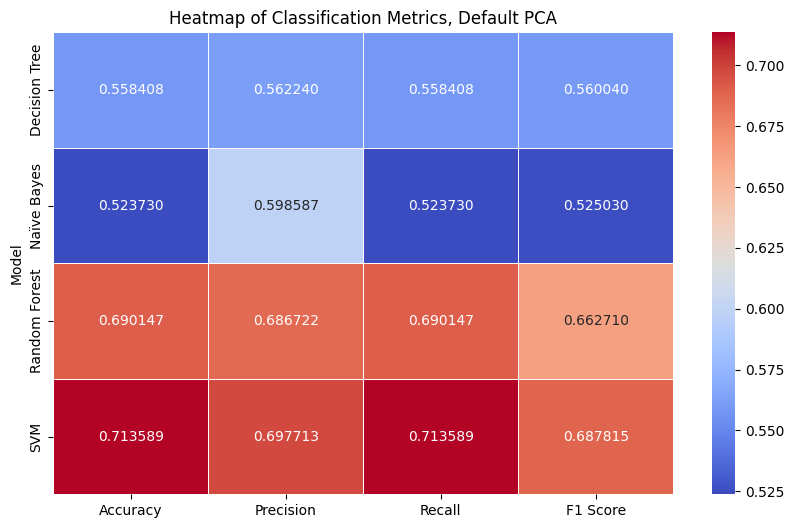

In [24]:
df_heatmap = evaluation_metrics_pca.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default PCA")
plt.show()

In this heatmap, the metrics were obtained after applying PCA by default to the data before training. Among the evaluated, the 2 best performing models are Random Forest and SVM; with SVM showing slightly better performance. This suggests that dimensionality reduction through PCA particularly benefits the SVM model, improving its generalization capability compared to other models like Decision Tree and Naïve Bayes.

In [25]:
SVM_df_hyperparameter_turning.groupby('Model').mean()


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Super Vector Machine GS,0.713589,0.697713,0.713589,0.687815
Support Vector Machine RS,0.707571,0.659468,0.707571,0.682248


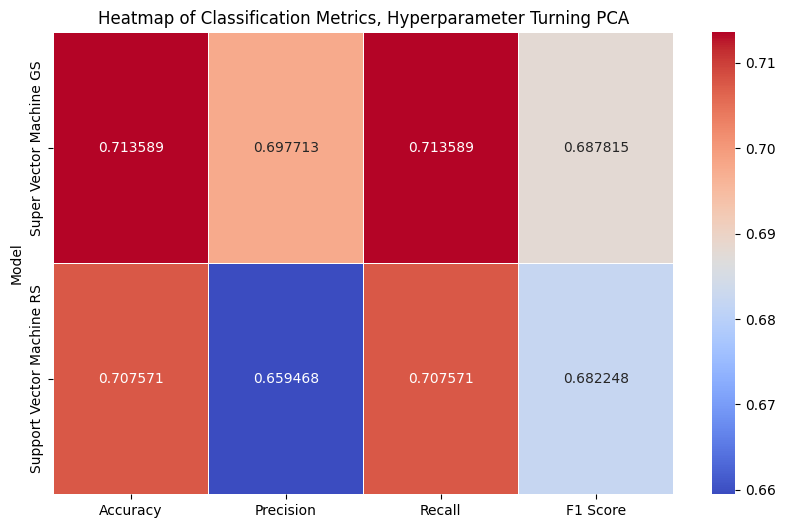

In [26]:
df_heatmap = SVM_df_hyperparameter_turning.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning PCA")
plt.show()

This heatmap compares the performance of SVM with Grid Search and Random Search after hyperparameter tuning with PCA applied. SVM with Grid Search stands out with the best results; achieving the same metrics as SVM with default PCA. This indicates that hyperparameter tuning through Grid Search not only optimizes the model but also reinforces the consistency of SVM's performance with PCA. On the other hand, Random Search shows slightly lower performance compared to Grid Search.

### **ANALYSIS: Models obtained with data trained without using PCA**

In [27]:
# Promedios por modelo by default sin PCA, valores escalados
evaluation_metrics_scaled.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree,0.627257,0.631138,0.627257,0.628868
Naïve Bayes,0.459590,0.578699,0.459590,0.464458
Random Forest,0.744013,0.740702,0.744013,0.722893
SVM,0.722216,0.699788,0.722216,0.696709


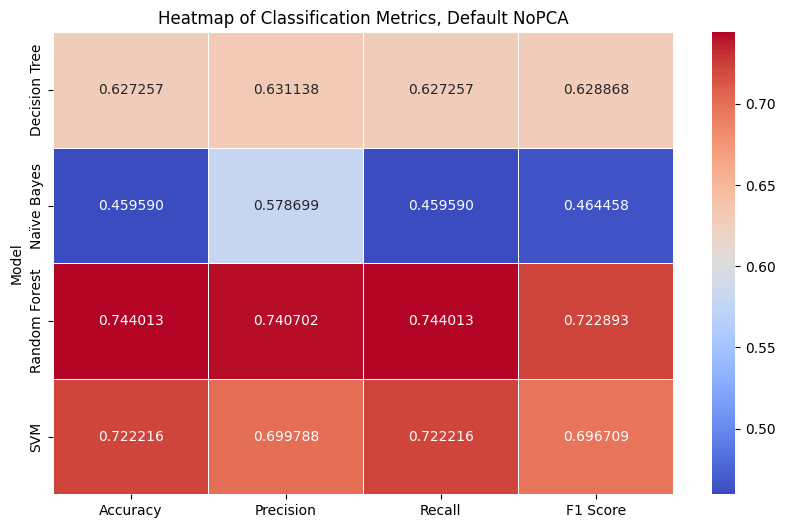

In [28]:
df_heatmap = evaluation_metrics_scaled.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Default NoPCA")
plt.show()

This heatmap evaluates the models without applying PCA. Once again, the two best models are Random Forest and SVM. However, in this case, Random Forest clearly outperforms SVM, achieving the highest metrics between all the evaluated models. This highlights that PCA has a negative impact on Random Forest's performance, suggesting that PCA might remove features critical for the model's effectiveness.


In [29]:
df_hyperparameter_turning_NoPCA.groupby('Model').mean()

,Accuracy,Precision,Recall,F1 Score
Model,,,,
RANDOM FOREST GS,0.677716,0.667004,0.677716,0.700458
Super Vector Machine GS,0.712056,0.707881,0.712056,0.688373
Support Vector Machine RS,0.707571,0.659476,0.707571,0.682246


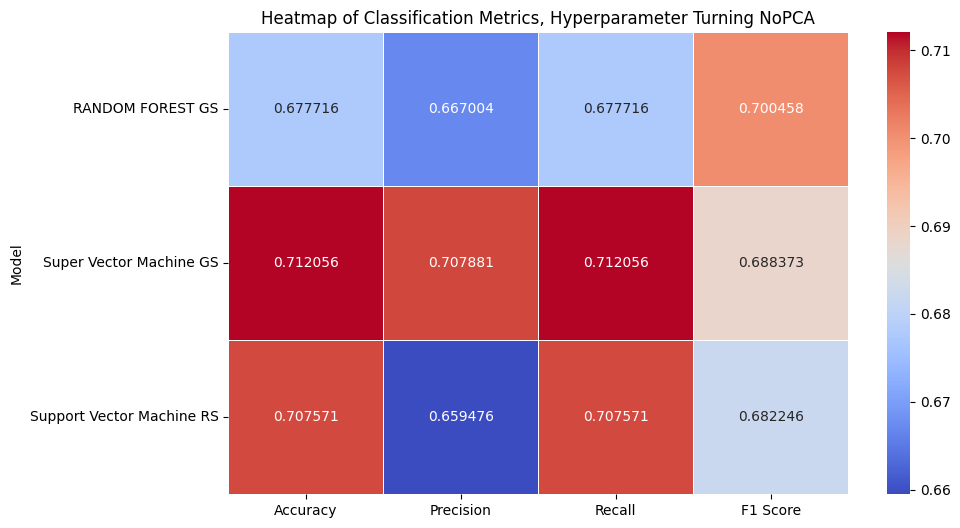

In [30]:
df_heatmap = df_hyperparameter_turning_NoPCA.groupby('Model').mean()

plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".6f", cmap="coolwarm", cbar=True, linewidths=0.5)
plt.title("Heatmap of Classification Metrics, Hyperparameter Turning NoPCA")
plt.show()

The final heatmap compares the performance of Random Forest with Grid Search, SVM with Random Search, and SVM with Grid Search, all without PCA. Random Forest shows slightly lower performance compared to its default configuration without PCA, indicating that hyperparameter tuning does not necessarily improve its results in this scenario. On the other hand, both SVM models achieve similar metrics, with SVM Grid Search being the best model overall.
From the analysis, it's clear that the performance of models like SVM and Random Forest depends heavily on whether PCA is applied. SVM shines when PCA is used, especially with Grid Search for hyperparameter tuning, showing consistent and reliable results. On the other hand, Random Forest performs much better without PCA, as it relies on the full set of features to build strong decision trees.
This shows that PCA isn't a one size fits all solution, it works great for SVM but can hurt Random Forest's performance. Ultimately, choosing the right combination of preprocessing and model depends on understanding how they interact, and SVM with Grid Search and PCA proves to be the most robust option overall.